# AIML Lab Exercise 4: A* Search Algorithm
**Problem:** Find the shortest route on the Romania road map using a heuristic, and find a path through a grid with obstacles

A\* is an **informed (heuristic) search** algorithm. It evaluates each node with

$$f(n) = g(n) + h(n)$$

- **g(n)** — actual cost from the start to node *n*
- **h(n)** — estimated cost from *n* to the goal (heuristic)

A\* always expands the node with the lowest *f(n)*. If the heuristic is **admissible** (never overestimates the true cost), A\* is guaranteed to find the optimal path while expanding far fewer nodes than uninformed search.

## 1. Import the required libraries

In [1]:
import heapq
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Represent the weighted graph (Romania road map)

In [2]:
edges = [
    ('Arad', 'Zerind', 75), ('Arad', 'Sibiu', 140), ('Arad', 'Timisoara', 118),
    ('Zerind', 'Oradea', 71), ('Oradea', 'Sibiu', 151), ('Timisoara', 'Lugoj', 111),
    ('Lugoj', 'Mehadia', 70), ('Mehadia', 'Drobeta', 75), ('Drobeta', 'Craiova', 120),
    ('Craiova', 'Rimnicu Vilcea', 146), ('Craiova', 'Pitesti', 138),
    ('Sibiu', 'Fagaras', 99), ('Sibiu', 'Rimnicu Vilcea', 80),
    ('Rimnicu Vilcea', 'Pitesti', 97), ('Fagaras', 'Bucharest', 211),
    ('Pitesti', 'Bucharest', 101), ('Bucharest', 'Giurgiu', 90),
    ('Bucharest', 'Urziceni', 85), ('Urziceni', 'Hirsova', 98), ('Hirsova', 'Eforie', 86),
    ('Urziceni', 'Vaslui', 142), ('Vaslui', 'Iasi', 92), ('Iasi', 'Neamt', 87),
]

# Undirected weighted graph as an adjacency list: {city: {neighbour: distance}}
graph = {}
for u, v, w in edges:
    graph.setdefault(u, {})[v] = w
    graph.setdefault(v, {})[u] = w

for city in sorted(graph):
    print(f"{city:15s} -> {graph[city]}")
print("\nNumber of cities:", len(graph))
print("Number of roads :", len(edges))

Arad            -> {'Zerind': 75, 'Sibiu': 140, 'Timisoara': 118}
Bucharest       -> {'Fagaras': 211, 'Pitesti': 101, 'Giurgiu': 90, 'Urziceni': 85}
Craiova         -> {'Drobeta': 120, 'Rimnicu Vilcea': 146, 'Pitesti': 138}
Drobeta         -> {'Mehadia': 75, 'Craiova': 120}
Eforie          -> {'Hirsova': 86}
Fagaras         -> {'Sibiu': 99, 'Bucharest': 211}
Giurgiu         -> {'Bucharest': 90}
Hirsova         -> {'Urziceni': 98, 'Eforie': 86}
Iasi            -> {'Vaslui': 92, 'Neamt': 87}
Lugoj           -> {'Timisoara': 111, 'Mehadia': 70}
Mehadia         -> {'Lugoj': 70, 'Drobeta': 75}
Neamt           -> {'Iasi': 87}
Oradea          -> {'Zerind': 71, 'Sibiu': 151}
Pitesti         -> {'Craiova': 138, 'Rimnicu Vilcea': 97, 'Bucharest': 101}
Rimnicu Vilcea  -> {'Craiova': 146, 'Sibiu': 80, 'Pitesti': 97}
Sibiu           -> {'Arad': 140, 'Oradea': 151, 'Fagaras': 99, 'Rimnicu Vilcea': 80}
Timisoara       -> {'Arad': 118, 'Lugoj': 111}
Urziceni        -> {'Bucharest': 85, 'Hirsova': 98, 

## 3. Define the heuristic function h(n)
We use the **straight-line distance (SLD)** from each city to Bucharest. A straight line is never longer than a road, so this heuristic is admissible.

In [3]:
h_sld = {
    'Arad': 366, 'Bucharest': 0, 'Craiova': 160, 'Drobeta': 242, 'Eforie': 161,
    'Fagaras': 176, 'Giurgiu': 77, 'Hirsova': 151, 'Iasi': 226, 'Lugoj': 244,
    'Mehadia': 241, 'Neamt': 234, 'Oradea': 380, 'Pitesti': 100, 'Rimnicu Vilcea': 193,
    'Sibiu': 253, 'Timisoara': 329, 'Urziceni': 80, 'Vaslui': 199, 'Zerind': 374,
}
display(pd.DataFrame(sorted(h_sld.items()), columns=['City', 'h(n) = SLD to Bucharest']))

,City,h(n) = SLD to Bucharest
0,Arad,366
1,Bucharest,0
2,Craiova,160
3,Drobeta,242
4,Eforie,161
5,Fagaras,176
6,Giurgiu,77
7,Hirsova,151
8,Iasi,226
9,Lugoj,244


## 4. Visualize the map with heuristic values
Each node shows the city name and its h(n) value.

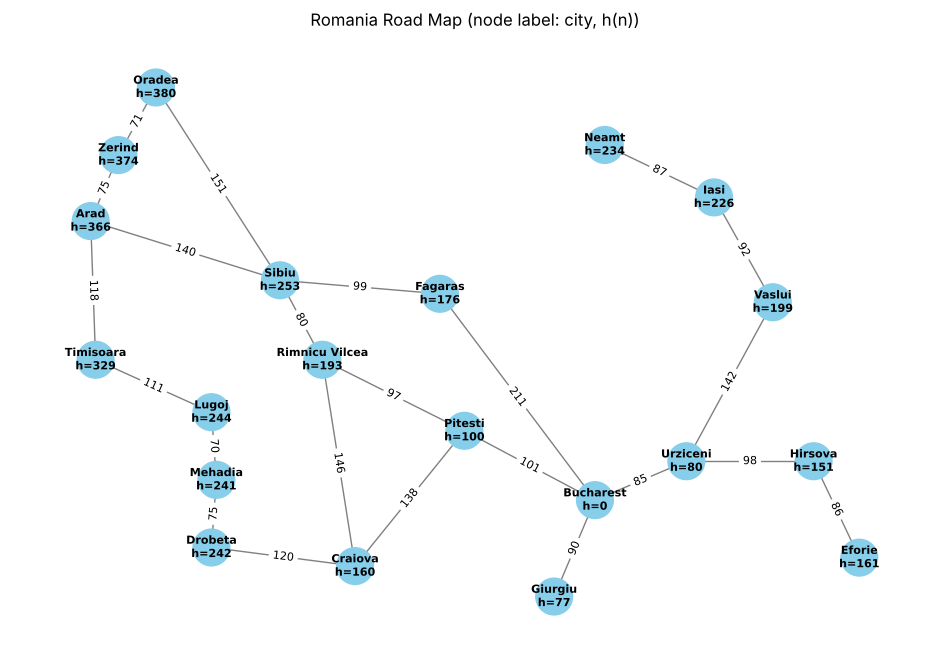

In [4]:
pos = {
    'Arad': (91, 492), 'Bucharest': (400, 327), 'Craiova': (253, 288), 'Drobeta': (165, 299),
    'Eforie': (562, 293), 'Fagaras': (305, 449), 'Giurgiu': (375, 270), 'Hirsova': (534, 350),
    'Iasi': (473, 506), 'Lugoj': (165, 379), 'Mehadia': (168, 339), 'Neamt': (406, 537),
    'Oradea': (131, 571), 'Pitesti': (320, 368), 'Rimnicu Vilcea': (233, 410),
    'Sibiu': (207, 457), 'Timisoara': (94, 410), 'Urziceni': (456, 350),
    'Vaslui': (509, 444), 'Zerind': (108, 531),
}

G = nx.Graph()
for u, v, w in edges:
    G.add_edge(u, v, weight=w)

def draw_map(path=None, title='Romania Road Map', node_labels=None):
    plt.figure(figsize=(12, 8))
    nx.draw_networkx_edges(G, pos, edge_color='gray')
    if path:
        nx.draw_networkx_edges(G, pos, edgelist=list(zip(path, path[1:])), edge_color='red', width=4)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'), font_size=8)
    colors = ['orange' if path and n in path else 'skyblue' for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=700)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8, font_weight='bold')
    plt.title(title)
    plt.axis('off')
    plt.show()

draw_map(title='Romania Road Map (node label: city, h(n))',
         node_labels={c: f"{c}\nh={h_sld[c]}" for c in G.nodes})

## 5. Implement the A* algorithm
**Algorithm:**
1. Push the start node into a priority queue with f = h(start), g = 0.
2. Pop the node with the **lowest f(n)**.
3. If it is the goal, return the path.
4. Otherwise, for every neighbour compute g' = g(n) + step cost and f' = g' + h(neighbour); push it if g' is better than any previously found cost.
5. Repeat until the queue is empty.

The same function also works as **Greedy Best-First Search** (priority = h only) and **Uniform Cost Search** (priority = g only), which we use later for comparison.

In [5]:
def best_first_search(graph, start, goal, h, mode='astar', trace=False):
    """mode: 'astar' -> f = g + h, 'greedy' -> f = h, 'ucs' -> f = g"""
    def priority(g, node):
        return {'astar': g + h[node], 'greedy': h[node], 'ucs': g}[mode]

    frontier = [(priority(0, start), 0, start, [start])]   # (f, g, node, path)
    best_g = {start: 0}
    explored = set()
    steps = []

    while frontier:
        f, g, node, path = heapq.heappop(frontier)
        if node in explored:
            continue
        if trace:
            steps.append({'Step': len(steps) + 1, 'Expanded node': node, 'g(n)': g, 'h(n)': h[node],
                          'f(n)': f, 'Frontier (node: f)': ', '.join(f"{n}: {fv}" for fv, _, n, _ in sorted(frontier))})
        if node == goal:
            return path, g, explored | {node}, pd.DataFrame(steps)
        explored.add(node)

        for neighbour, step_cost in graph[node].items():
            new_g = g + step_cost
            if neighbour not in explored and new_g < best_g.get(neighbour, float('inf')):
                best_g[neighbour] = new_g
                heapq.heappush(frontier, (priority(new_g, neighbour), new_g, neighbour, path + [neighbour]))

    return None, float('inf'), explored, pd.DataFrame(steps)

def a_star(graph, start, goal, h, trace=False):
    return best_first_search(graph, start, goal, h, mode='astar', trace=trace)

print("A* function defined.")

A* function defined.


## 6. Find the shortest path from Arad to Bucharest using A*

In [6]:
path, cost, expanded, trace = a_star(graph, 'Arad', 'Bucharest', h_sld, trace=True)
print("Optimal path  :", ' -> '.join(path))
print("Total cost    :", cost, "km")
print("Nodes expanded:", len(expanded), "->", sorted(expanded))

Optimal path  : Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
Total cost    : 418 km
Nodes expanded: 6 -> ['Arad', 'Bucharest', 'Fagaras', 'Pitesti', 'Rimnicu Vilcea', 'Sibiu']


## 7. Trace the A* search (g, h and f values at each step)

In [7]:
pd.set_option('display.max_colwidth', None)
display(trace)

,Step,Expanded node,g(n),h(n),f(n),Frontier (node: f)
0,1,Arad,0,366,366,
1,2,Sibiu,140,253,393,"Timisoara: 447, Zerind: 449"
2,3,Rimnicu Vilcea,220,193,413,"Fagaras: 415, Timisoara: 447, Zerind: 449, Oradea: 671"
3,4,Fagaras,239,176,415,"Pitesti: 417, Timisoara: 447, Zerind: 449, Craiova: 526, Oradea: 671"
4,5,Pitesti,317,100,417,"Timisoara: 447, Zerind: 449, Bucharest: 450, Craiova: 526, Oradea: 671"
5,6,Bucharest,418,0,418,"Timisoara: 447, Zerind: 449, Bucharest: 450, Craiova: 526, Oradea: 671"


**Interpretation:** After expanding Sibiu, Rimnicu Vilcea (f = 413) is chosen before Fagaras (f = 415). Bucharest is first reached via Fagaras with f = 450, but A\* keeps exploring because Pitesti has a lower f (417). Through Pitesti, Bucharest is reached with f = 418, which is then expanded as the goal.

## 8. Visualize the A* path

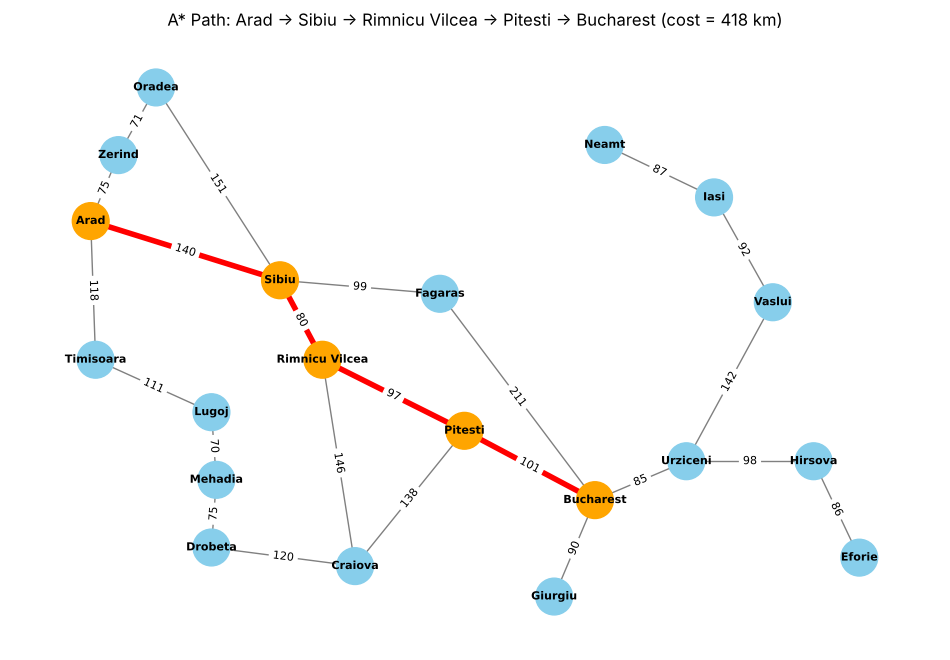

In [8]:
draw_map(path, title=f"A* Path: {' -> '.join(path)} (cost = {cost} km)")

## 9. Compare A* with Greedy Best-First Search and Uniform Cost Search

,Path,Cost (km),Nodes expanded
Algorithm,,,
Greedy Best-First (f = h),Arad -> Sibiu -> Fagaras -> Bucharest,450,4
Uniform Cost Search (f = g),Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest,418,13
A* (f = g + h),Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest,418,6


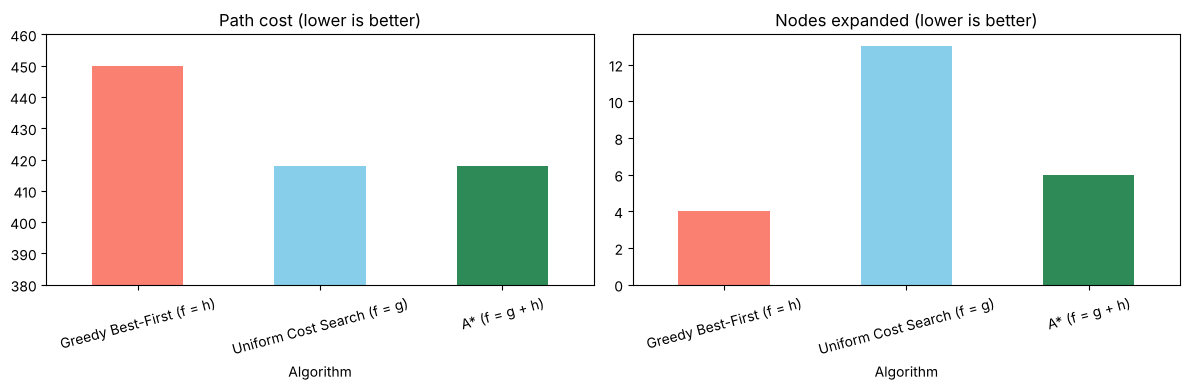

In [9]:
rows = []
for name, mode in [('Greedy Best-First (f = h)', 'greedy'), ('Uniform Cost Search (f = g)', 'ucs'), ('A* (f = g + h)', 'astar')]:
    p, c, exp, _ = best_first_search(graph, 'Arad', 'Bucharest', h_sld, mode=mode)
    rows.append({'Algorithm': name, 'Path': ' -> '.join(p), 'Cost (km)': c, 'Nodes expanded': len(exp)})
comparison = pd.DataFrame(rows).set_index('Algorithm')
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison['Cost (km)'].plot.bar(ax=axes[0], color=['salmon', 'skyblue', 'seagreen'], rot=15)
axes[0].set_title('Path cost (lower is better)')
axes[0].set_ylim(380, 460)
comparison['Nodes expanded'].plot.bar(ax=axes[1], color=['salmon', 'skyblue', 'seagreen'], rot=15)
axes[1].set_title('Nodes expanded (lower is better)')
plt.tight_layout()
plt.show()

**Interpretation:**
- **Greedy Best-First** is fast but **not optimal** — it goes straight towards the goal through Fagaras (450 km).
- **UCS** is optimal (418 km) but expands many nodes because it has no idea where the goal is.
- **A\*** combines both: it is **optimal** like UCS and expands **fewer nodes** thanks to the heuristic.

## 10. Check that the heuristic is admissible
A heuristic is admissible if **h(n) ≤ h\*(n)** for every node, where h\*(n) is the true cheapest cost from *n* to the goal. We compute h\*(n) with UCS and compare.

In [10]:
rows = []
for city in sorted(graph):
    _, true_cost, _, _ = best_first_search(graph, city, 'Bucharest', h_sld, mode='ucs')
    rows.append({'City': city, 'h(n) (SLD)': h_sld[city], 'h*(n) (true cost)': true_cost,
                 'Admissible (h <= h*)': h_sld[city] <= true_cost})
admissibility = pd.DataFrame(rows)
display(admissibility)
print("Heuristic is admissible for all cities:", admissibility['Admissible (h <= h*)'].all())

,City,h(n) (SLD),h*(n) (true cost),Admissible (h <= h*)
0,Arad,366,418,True
1,Bucharest,0,0,True
2,Craiova,160,239,True
3,Drobeta,242,359,True
4,Eforie,161,269,True
5,Fagaras,176,211,True
6,Giurgiu,77,90,True
7,Hirsova,151,183,True
8,Iasi,226,319,True
9,Lugoj,244,504,True


Heuristic is admissible for all cities: True


## 11. A* on a 2D grid with obstacles
A\* is widely used for path finding in games and robotics. Here each cell of a 20×20 grid is a node, `1` is an obstacle, and the agent can move up, down, left or right with cost 1. We use the **Manhattan distance** as the heuristic:

$$h(n) = |x_n - x_{goal}| + |y_n - y_{goal}|$$

In [11]:
grid = np.zeros((20, 20), dtype=int)
grid[0:15, 6] = 1          # wall from the top edge (gap at the bottom)
grid[5:20, 13] = 1         # wall from the bottom edge (gap at the top)
start, goal = (0, 0), (19, 19)

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def grid_search(grid, start, goal, use_heuristic=True):
    """A* when use_heuristic=True, Dijkstra / UCS (h = 0) otherwise."""
    h = (lambda n: manhattan(n, goal)) if use_heuristic else (lambda n: 0)
    # Heap entries are (f, h, g, cell): ties on f are broken in favour of the cell closer to the goal
    frontier = [(h(start), h(start), 0, start)]
    parent, best_g, explored = {start: None}, {start: 0}, set()
    while frontier:
        f, _, g, cell = heapq.heappop(frontier)
        if cell in explored:
            continue
        explored.add(cell)
        if cell == goal:
            break
        r, c = cell
        for nr, nc in [(r + 1, c), (r - 1, c), (r, c + 1), (r, c - 1)]:
            if 0 <= nr < grid.shape[0] and 0 <= nc < grid.shape[1] and grid[nr, nc] == 0:
                ng = g + 1
                if ng < best_g.get((nr, nc), float('inf')):
                    best_g[(nr, nc)] = ng
                    parent[(nr, nc)] = cell
                    heapq.heappush(frontier, (ng + h((nr, nc)), h((nr, nc)), ng, (nr, nc)))
    path, cell = [], goal
    while cell is not None:
        path.append(cell)
        cell = parent[cell]
    return path[::-1], explored

astar_path, astar_explored = grid_search(grid, start, goal, use_heuristic=True)
dijkstra_path, dijkstra_explored = grid_search(grid, start, goal, use_heuristic=False)
print(f"A*      : path length = {len(astar_path) - 1}, cells explored = {len(astar_explored)}")
print(f"Dijkstra: path length = {len(dijkstra_path) - 1}, cells explored = {len(dijkstra_explored)}")

A*      : path length = 60, cells explored = 238
Dijkstra: path length = 60, cells explored = 370


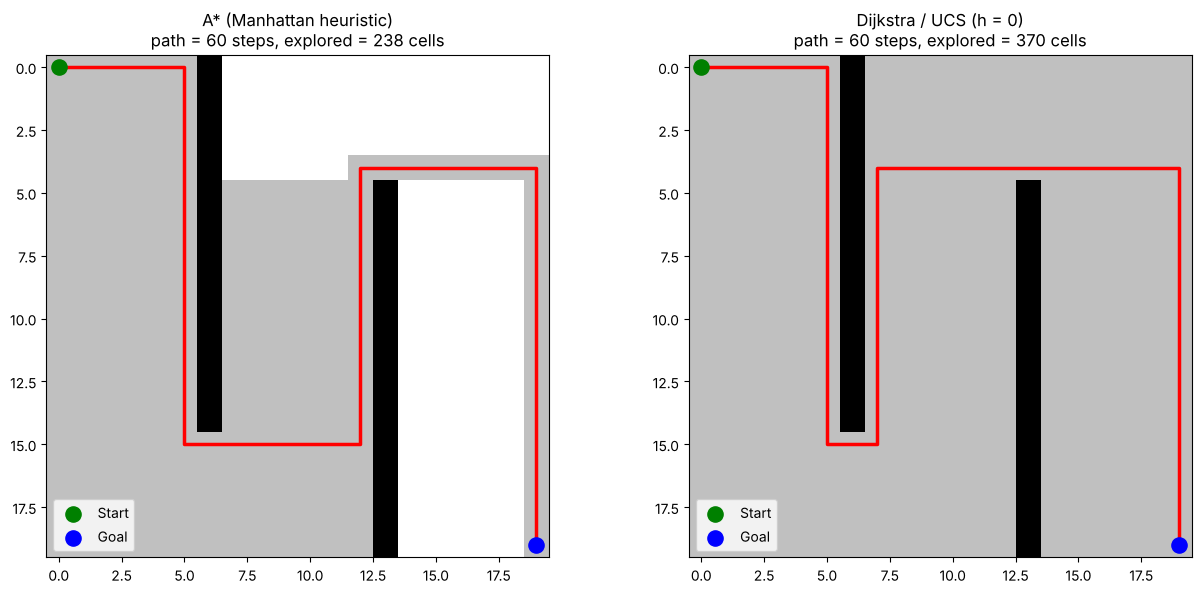

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, p, explored, title in [(axes[0], astar_path, astar_explored, 'A* (Manhattan heuristic)'),
                               (axes[1], dijkstra_path, dijkstra_explored, 'Dijkstra / UCS (h = 0)')]:
    canvas = np.where(grid == 1, 0.0, 1.0)
    for cell in explored:
        canvas[cell] = 0.75                          # explored cells in light grey
    ax.imshow(canvas, cmap='gray', vmin=0, vmax=1)
    rows, cols = zip(*p)
    ax.plot(cols, rows, color='red', linewidth=2.5)
    ax.scatter([start[1]], [start[0]], color='green', s=120, zorder=3, label='Start')
    ax.scatter([goal[1]], [goal[0]], color='blue', s=120, zorder=3, label='Goal')
    ax.set_title(f"{title}\npath = {len(p) - 1} steps, explored = {len(explored)} cells")
    ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

**Interpretation:** Both algorithms find a path of the same (optimal) length, but A\* explores far fewer cells (light grey) because the heuristic guides it towards the goal.

## 12. Documentation summary
1. Represented the Romania road map as a weighted graph and defined the straight-line-distance heuristic
2. Implemented A\* using a priority queue ordered by f(n) = g(n) + h(n)
3. Found the optimal path from Arad to Bucharest and traced g, h and f at every step
4. Visualized the path on the map
5. Compared A\* with Greedy Best-First Search and Uniform Cost Search (cost and nodes expanded)
6. Verified that the heuristic is admissible (h(n) ≤ true cost for every city)
7. Applied A\* to a grid path-finding problem with the Manhattan heuristic and compared it with Dijkstra

**Result:** A\* was implemented successfully. It found the optimal path **Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest (418 km)** while expanding fewer nodes than Uniform Cost Search.